# 🔍 Adaptive Threat Hunt — Exploratory Analysis

**Dataset:** NSL-KDD (University of New Brunswick)  
**Goal:** Understand the feature space, class distribution, and model behavior before deployment.

This notebook covers:
1. Dataset overview & class distribution
2. Feature distributions (normal vs. attack)
3. Correlation heatmap
4. Anomaly score distributions per model
5. PCA visualization of the decision boundary

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from urllib.request import urlretrieve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.decomposition import PCA
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Plotting style
plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor': '#1a1d27',
    'axes.edgecolor': '#444',
    'axes.labelcolor': '#ccc',
    'xtick.color': '#aaa',
    'ytick.color': '#aaa',
    'text.color': '#eee',
    'grid.color': '#333',
    'grid.linewidth': 0.5,
    'font.family': 'monospace',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
ATTACK_COLOR = '#e74c3c'
NORMAL_COLOR = '#2ecc71'
HIGHLIGHT    = '#f39c12'

print('Libraries loaded ✅')

Libraries loaded ✅


In [2]:
# ── NSL-KDD Column Names ──────────────────────────────────────────────────────
COLUMNS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes',
    'land','wrong_fragment','urgent','hot','num_failed_logins','logged_in',
    'num_compromised','root_shell','su_attempted','num_root','num_file_creations',
    'num_shells','num_access_files','num_outbound_cmds','is_host_login',
    'is_guest_login','count','srv_count','serror_rate','srv_serror_rate',
    'rerror_rate','srv_rerror_rate','same_srv_rate','diff_srv_rate',
    'srv_diff_host_rate','dst_host_count','dst_host_srv_count',
    'dst_host_same_srv_rate','dst_host_diff_srv_rate','dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate','dst_host_serror_rate','dst_host_srv_serror_rate',
    'dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty'
]

CACHE_DIR = Path('../data/nslkdd')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_URL = 'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain+.txt'
TEST_URL  = 'https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest+.txt'
TRAIN_PATH = CACHE_DIR / 'KDDTrain+.txt'
TEST_PATH  = CACHE_DIR / 'KDDTest+.txt'

if not TRAIN_PATH.exists():
    print('Downloading NSL-KDD train set...')
    urlretrieve(TRAIN_URL, TRAIN_PATH)
if not TEST_PATH.exists():
    print('Downloading NSL-KDD test set...')
    urlretrieve(TEST_URL, TEST_PATH)

df_train = pd.read_csv(TRAIN_PATH, header=None, names=COLUMNS)
df_test  = pd.read_csv(TEST_PATH,  header=None, names=COLUMNS)
df_all   = pd.concat([df_train, df_test], ignore_index=True)

# Binary label: 'normal' → 0, everything else → 1 (attack)
df_all['is_attack'] = (df_all['label'] != 'normal').astype(int)
df_train['is_attack'] = (df_train['label'] != 'normal').astype(int)
df_test['is_attack']  = (df_test['label']  != 'normal').astype(int)

print(f'Train rows: {len(df_train):,}  |  Test rows: {len(df_test):,}  |  Total: {len(df_all):,}')
print(f'Features: {df_all.shape[1]}  |  Attack rate (all): {df_all["is_attack"].mean()*100:.1f}%')

Train rows: 125,973  |  Test rows: 22,544  |  Total: 148,517
Features: 44  |  Attack rate (all): 48.1%


## 2. Class & Attack-Type Distribution

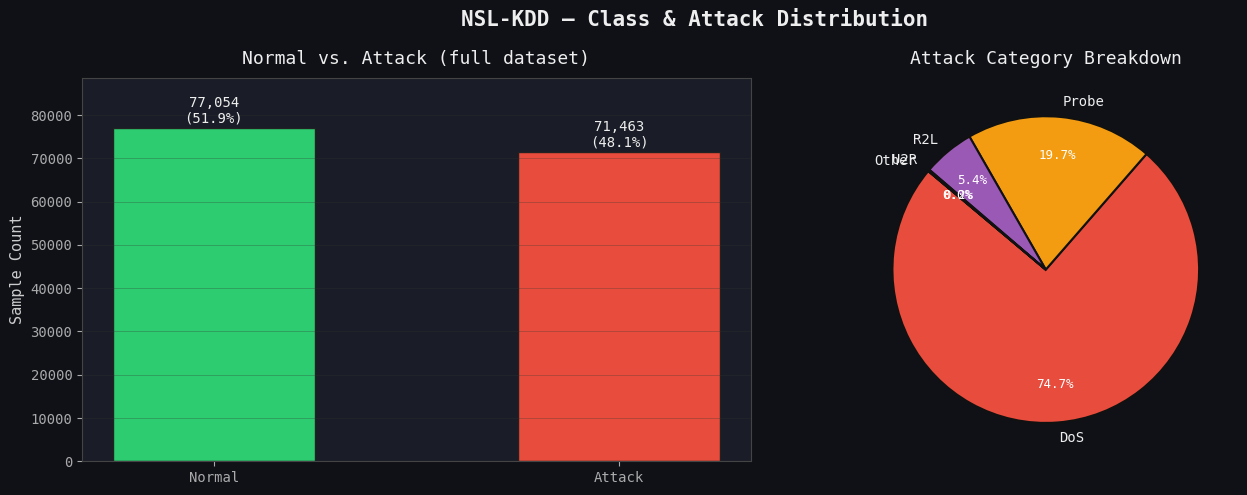

Saved → results/01_class_distribution.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NSL-KDD — Class & Attack Distribution', fontsize=15, fontweight='bold', color='#eee')

# ── Left: normal vs attack ────────────────────────────────────────────────────
ax = axes[0]
counts = df_all['is_attack'].value_counts()
bars = ax.bar(['Normal', 'Attack'], counts.values,
              color=[NORMAL_COLOR, ATTACK_COLOR], width=0.5, edgecolor='#222')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'{val:,}\n({val/len(df_all)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, color='#eee')
ax.set_title('Normal vs. Attack (full dataset)', pad=10)
ax.set_ylabel('Sample Count')
ax.grid(axis='y', alpha=0.4)
ax.set_ylim(0, max(counts.values) * 1.15)

# ── Right: attack category breakdown ─────────────────────────────────────────
ax = axes[1]

ATTACK_MAP = {
    'normal': 'Normal',
    'neptune':'DoS','back':'DoS','land':'DoS','pod':'DoS','smurf':'DoS',
    'teardrop':'DoS','mailbomb':'DoS','apache2':'DoS','processtable':'DoS','udpstorm':'DoS',
    'ipsweep':'Probe','nmap':'Probe','portsweep':'Probe','satan':'Probe',
    'mscan':'Probe','saint':'Probe',
    'ftp_write':'R2L','guess_passwd':'R2L','imap':'R2L','multihop':'R2L',
    'phf':'R2L','spy':'R2L','warezclient':'R2L','warezmaster':'R2L',
    'sendmail':'R2L','named':'R2L','snmpgetattack':'R2L','snmpguess':'R2L',
    'xlock':'R2L','xsnoop':'R2L','httptunnel':'R2L',
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R','rootkit':'U2R',
    'ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}
df_all['attack_cat'] = df_all['label'].map(ATTACK_MAP).fillna('Other')
cat_counts = df_all[df_all['attack_cat'] != 'Normal']['attack_cat'].value_counts()

cat_colors = {'DoS': '#e74c3c', 'Probe': '#f39c12', 'R2L': '#9b59b6', 'U2R': '#e67e22', 'Other': '#95a5a6'}
colors = [cat_colors.get(c, '#aaa') for c in cat_counts.index]
wedges, texts, autotexts = ax.pie(
    cat_counts.values, labels=cat_counts.index,
    autopct='%1.1f%%', colors=colors,
    pctdistance=0.75, startangle=140,
    wedgeprops={'edgecolor': '#111', 'linewidth': 1.5}
)
for t in texts: t.set_color('#eee')
for t in autotexts: t.set_color('#fff'); t.set_fontsize(9)
ax.set_title('Attack Category Breakdown', pad=10)

plt.tight_layout()
plt.savefig('../results/01_class_distribution.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print('Saved → results/01_class_distribution.png')

## 3. Feature Engineering & Preprocessing

In [4]:
# Encode categoricals, drop label columns
def preprocess(df):
    d = df.copy()
    for col in ['protocol_type', 'service', 'flag']:
        d[col] = LabelEncoder().fit_transform(d[col].astype(str))
    drop = ['label', 'difficulty', 'is_attack', 'attack_cat'] if 'attack_cat' in d.columns else ['label', 'difficulty', 'is_attack']
    X = d.drop(columns=[c for c in drop if c in d.columns])
    y = d['is_attack'].values
    return X.values.astype(float), y

X_train, y_train = preprocess(df_train)
X_test,  y_test  = preprocess(df_test)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

feature_names = df_train.drop(columns=['label','difficulty','is_attack']).columns.tolist()
print(f'X_train: {X_train_s.shape}  |  X_test: {X_test_s.shape}')
print(f'Features ({len(feature_names)}): {feature_names[:8]} ...')

X_train: (125973, 41)  |  X_test: (22544, 41)
Features (41): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment'] ...


## 4. Feature Distributions — Normal vs. Attack

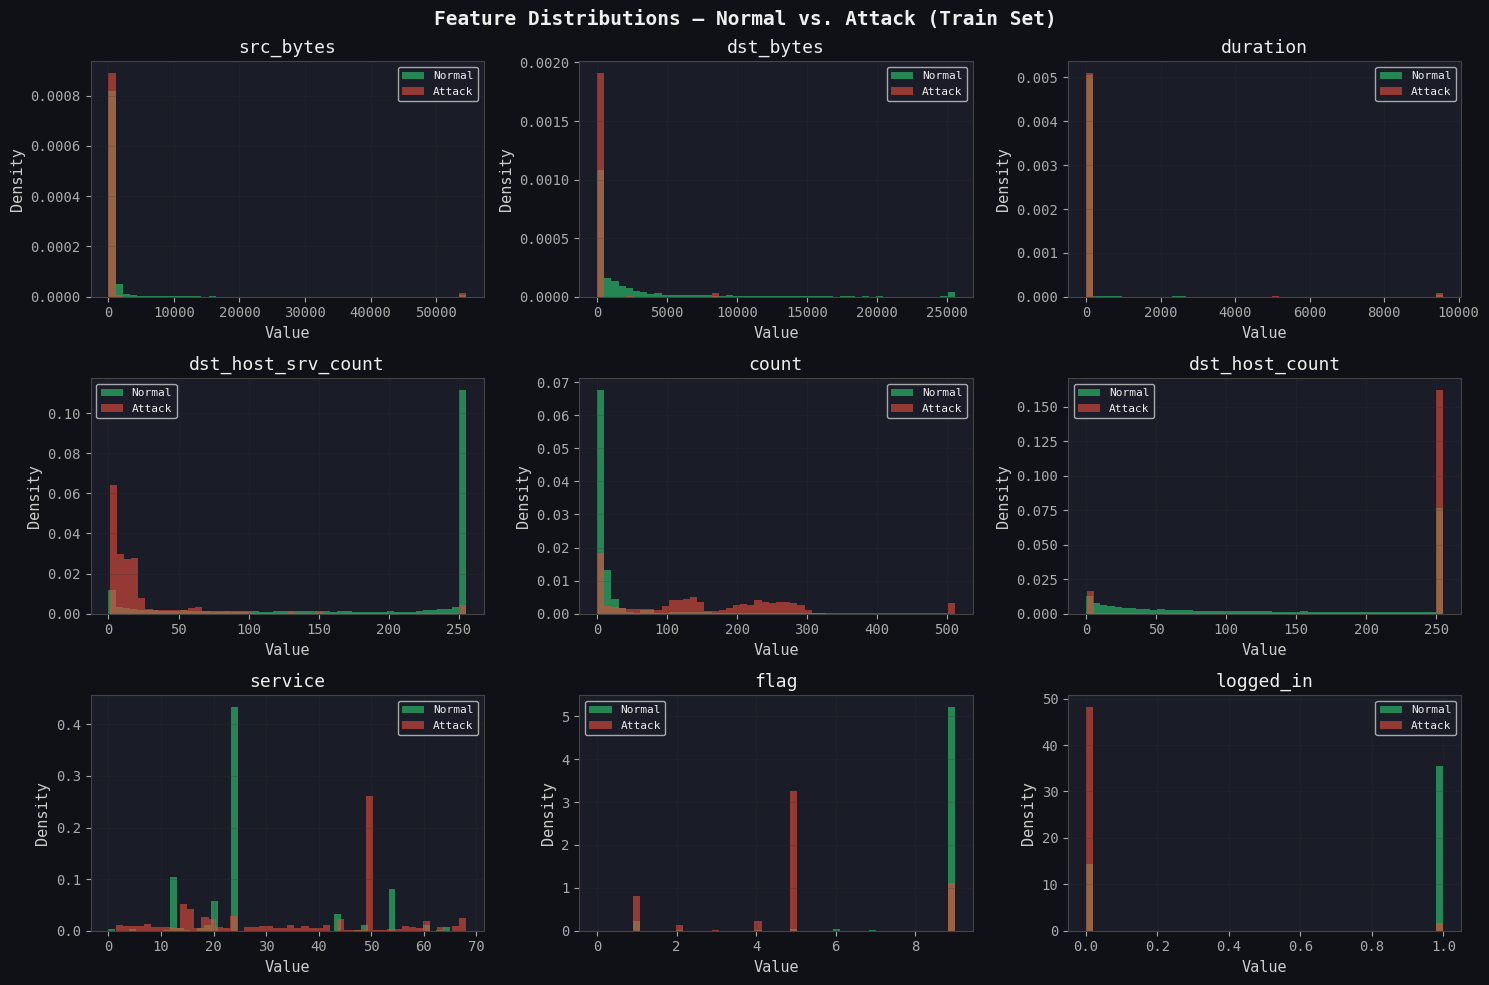

Saved → results/02_feature_distributions.png


In [5]:
# Top features by mean absolute difference between normal and attack
df_feat = pd.DataFrame(X_train, columns=feature_names)
df_feat['is_attack'] = y_train

normal_means = df_feat[df_feat['is_attack']==0].mean()
attack_means = df_feat[df_feat['is_attack']==1].mean()
diff = (attack_means - normal_means).abs().drop('is_attack').sort_values(ascending=False)
top_features = diff.head(9).index.tolist()

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
fig.suptitle('Feature Distributions — Normal vs. Attack (Train Set)', fontsize=14, fontweight='bold', color='#eee')

for ax, feat in zip(axes.flat, top_features):
    normal_vals = df_feat[df_feat['is_attack']==0][feat].clip(upper=df_feat[feat].quantile(0.99))
    attack_vals = df_feat[df_feat['is_attack']==1][feat].clip(upper=df_feat[feat].quantile(0.99))

    ax.hist(normal_vals, bins=50, alpha=0.6, color=NORMAL_COLOR, label='Normal', density=True)
    ax.hist(attack_vals, bins=50, alpha=0.6, color=ATTACK_COLOR, label='Attack', density=True)
    ax.set_title(feat, pad=6)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.savefig('../results/02_feature_distributions.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print('Saved → results/02_feature_distributions.png')

## 5. Correlation Heatmap

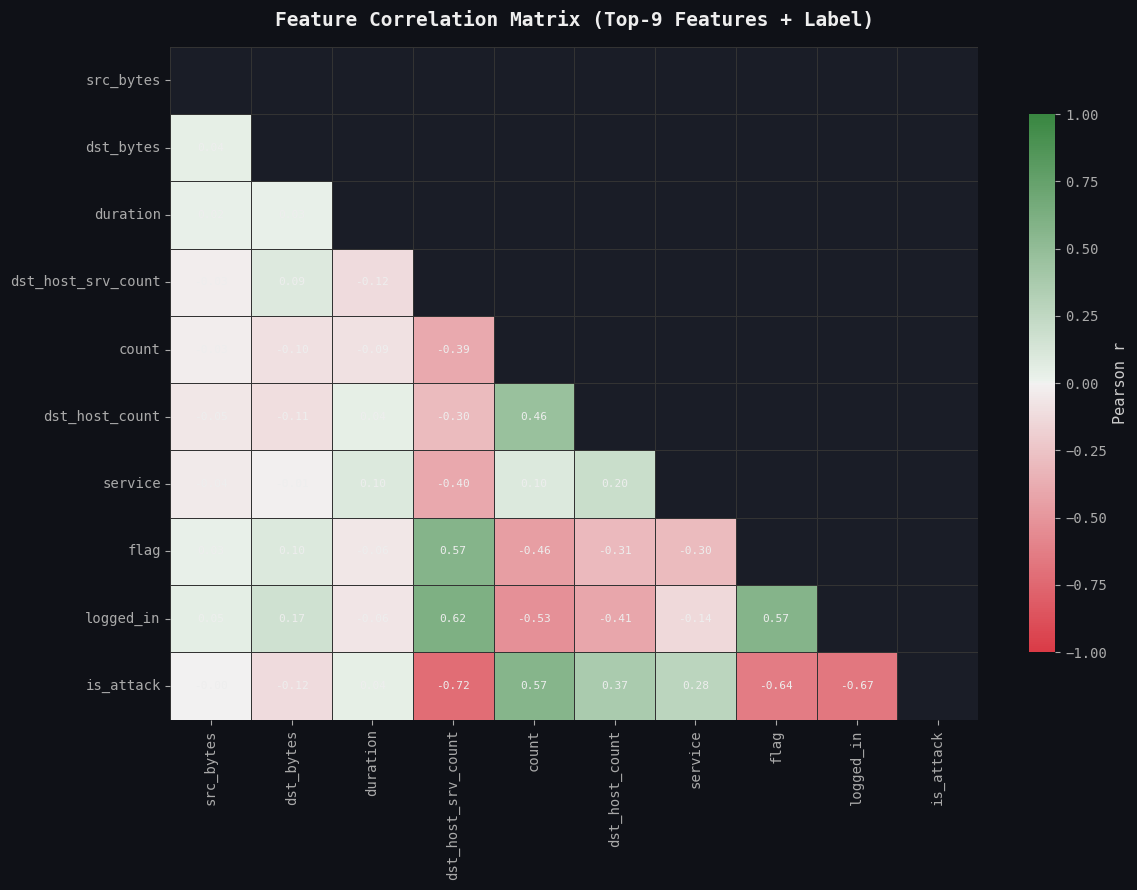

Saved → results/03_correlation_heatmap.png


In [6]:
# Compute correlation on a sample to keep it fast
sample = df_feat.sample(min(5000, len(df_feat)), random_state=42)
corr = sample[top_features + ['is_attack']].corr()

fig, ax = plt.subplots(figsize=(12, 9))
fig.patch.set_facecolor('#0f1117')
ax.set_facecolor('#1a1d27')

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

sns.heatmap(
    corr, mask=mask, ax=ax,
    cmap=sns.diverging_palette(10, 130, as_cmap=True),
    center=0, vmin=-1, vmax=1,
    annot=True, fmt='.2f', annot_kws={'size': 8, 'color': '#eee'},
    linewidths=0.5, linecolor='#333',
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}
)
ax.set_title('Feature Correlation Matrix (Top-9 Features + Label)', fontsize=14, fontweight='bold', color='#eee', pad=15)
ax.tick_params(colors='#aaa')

plt.tight_layout()
plt.savefig('../results/03_correlation_heatmap.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print('Saved → results/03_correlation_heatmap.png')

## 6. Model Anomaly Score Distributions

In [7]:
print('Training models (this may take ~30s)...')

# Isolation Forest
contamination = y_train.mean()
if_model = IsolationForest(n_estimators=100, contamination=contamination, random_state=42, n_jobs=-1)
if_model.fit(X_train_s)
if_scores = -if_model.score_samples(X_test_s)  # higher = more anomalous

# LOF (novelty mode)
lof_model = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=contamination, n_jobs=-1)
lof_model.fit(X_train_s)
lof_scores = -lof_model.score_samples(X_test_s)

# One-Class SVM (subsampled)
idx = np.random.RandomState(42).choice(len(X_train_s), min(15000, len(X_train_s)), replace=False)
ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=contamination)
ocsvm.fit(X_train_s[idx])
ocsvm_scores = -ocsvm.score_samples(X_test_s)

print('Done ✅')

Training models (this may take ~30s)...
Done ✅


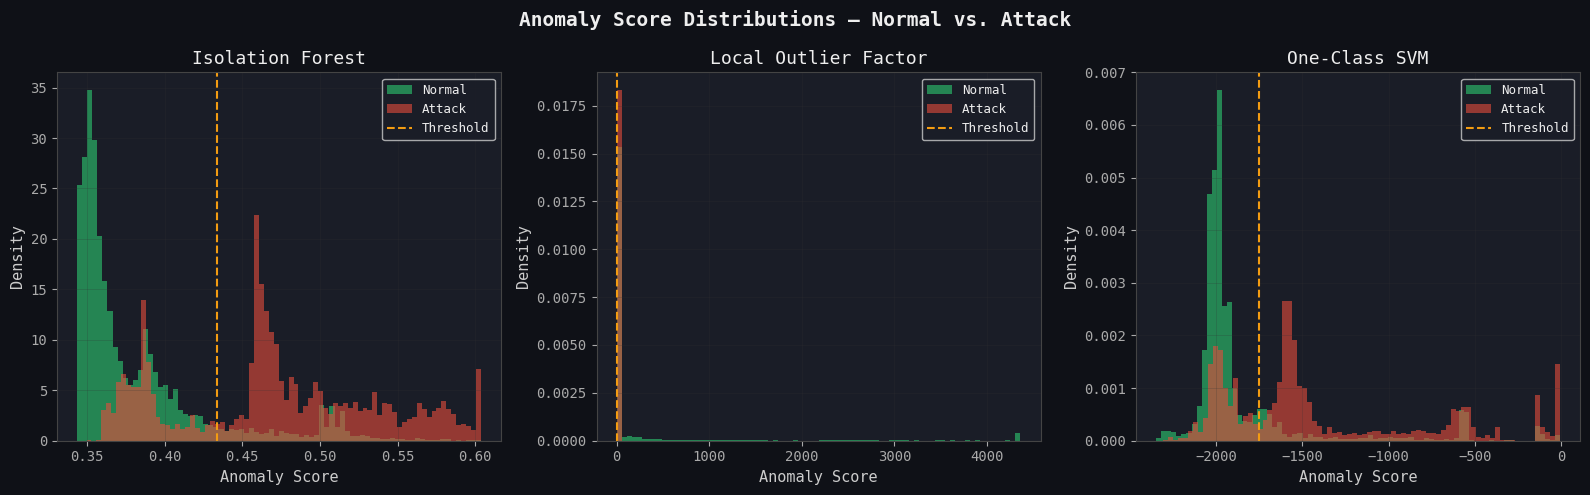

Saved → results/04_anomaly_scores.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Anomaly Score Distributions — Normal vs. Attack', fontsize=14, fontweight='bold', color='#eee')

models_scores = [
    ('Isolation Forest', if_scores),
    ('Local Outlier Factor', lof_scores),
    ('One-Class SVM', ocsvm_scores)
]

for ax, (name, scores) in zip(axes, models_scores):
    p99 = np.percentile(scores, 99)
    normal_s = scores[y_test == 0]
    attack_s = scores[y_test == 1]

    ax.hist(np.clip(normal_s, None, p99), bins=80, alpha=0.6,
            color=NORMAL_COLOR, label='Normal', density=True)
    ax.hist(np.clip(attack_s, None, p99), bins=80, alpha=0.6,
            color=ATTACK_COLOR, label='Attack', density=True)

    threshold = np.percentile(scores, (1 - contamination) * 100)
    ax.axvline(threshold, color=HIGHLIGHT, linestyle='--', linewidth=1.5, label=f'Threshold')

    ax.set_title(name)
    ax.set_xlabel('Anomaly Score')
    ax.set_ylabel('Density')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/04_anomaly_scores.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print('Saved → results/04_anomaly_scores.png')

## 7. PCA — 2D Decision Boundary Visualization

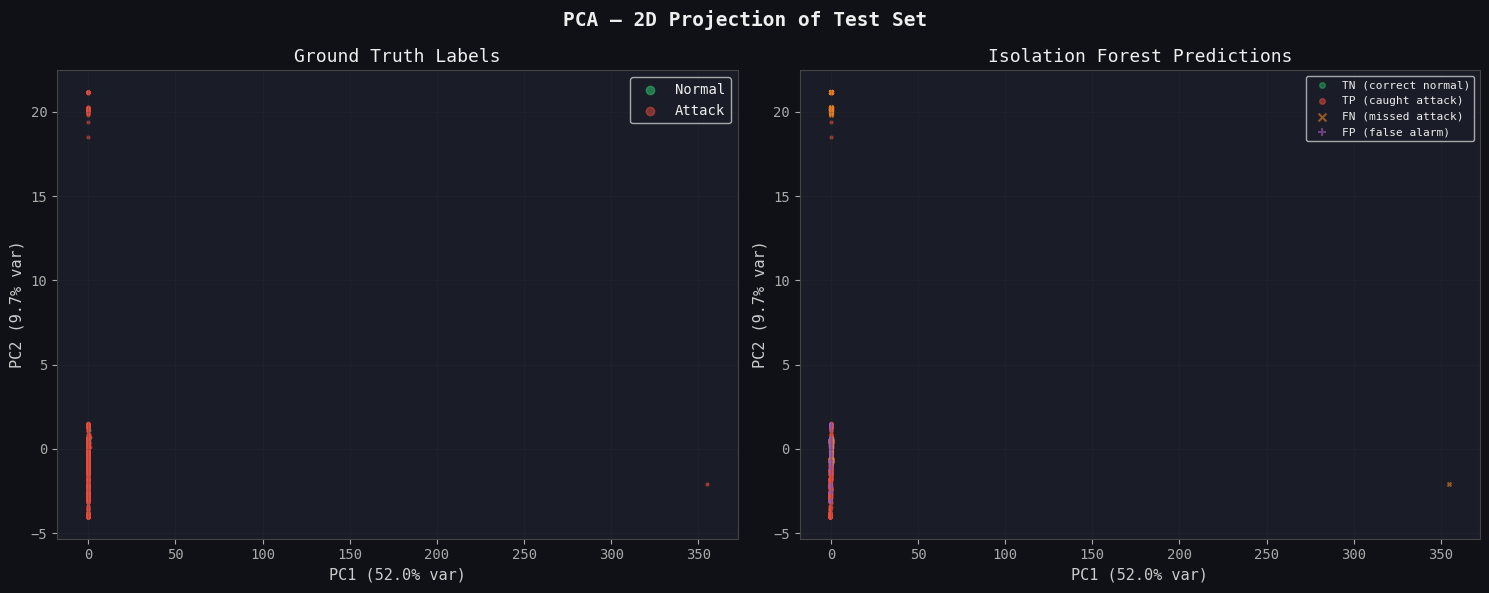

Saved → results/05_pca_visualization.png


In [9]:
# Project test set to 2D using PCA, then color by IF prediction
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_test_s)

# IF predictions
if_preds = (if_scores > np.percentile(if_scores, (1 - contamination) * 100)).astype(int)

var_explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('PCA — 2D Projection of Test Set', fontsize=14, fontweight='bold', color='#eee')

sample_idx = np.random.RandomState(42).choice(len(X_2d), min(3000, len(X_2d)), replace=False)

# ── Left: ground truth ──
ax = axes[0]
normal_idx = sample_idx[y_test[sample_idx] == 0]
attack_idx = sample_idx[y_test[sample_idx] == 1]
ax.scatter(X_2d[normal_idx, 0], X_2d[normal_idx, 1],
           c=NORMAL_COLOR, s=4, alpha=0.5, label='Normal')
ax.scatter(X_2d[attack_idx, 0], X_2d[attack_idx, 1],
           c=ATTACK_COLOR, s=4, alpha=0.5, label='Attack')
ax.set_title('Ground Truth Labels')
ax.set_xlabel(f'PC1 ({var_explained[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({var_explained[1]*100:.1f}% var)')
ax.legend(markerscale=3)
ax.grid(alpha=0.3)

# ── Right: Isolation Forest predictions ──
ax = axes[1]
tp_idx = sample_idx[(y_test[sample_idx]==1) & (if_preds[sample_idx]==1)]
tn_idx = sample_idx[(y_test[sample_idx]==0) & (if_preds[sample_idx]==0)]
fp_idx = sample_idx[(y_test[sample_idx]==0) & (if_preds[sample_idx]==1)]
fn_idx = sample_idx[(y_test[sample_idx]==1) & (if_preds[sample_idx]==0)]

ax.scatter(X_2d[tn_idx, 0], X_2d[tn_idx, 1], c=NORMAL_COLOR, s=4, alpha=0.4, label='TN (correct normal)')
ax.scatter(X_2d[tp_idx, 0], X_2d[tp_idx, 1], c=ATTACK_COLOR, s=4, alpha=0.5, label='TP (caught attack)')
ax.scatter(X_2d[fn_idx, 0], X_2d[fn_idx, 1], c='#e67e22', s=8, alpha=0.6, label='FN (missed attack)', marker='x')
ax.scatter(X_2d[fp_idx, 0], X_2d[fp_idx, 1], c='#9b59b6', s=8, alpha=0.6, label='FP (false alarm)', marker='+')

ax.set_title('Isolation Forest Predictions')
ax.set_xlabel(f'PC1 ({var_explained[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({var_explained[1]*100:.1f}% var)')
ax.legend(markerscale=2, fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/05_pca_visualization.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print('Saved → results/05_pca_visualization.png')

## 8. Precision-Recall Curves

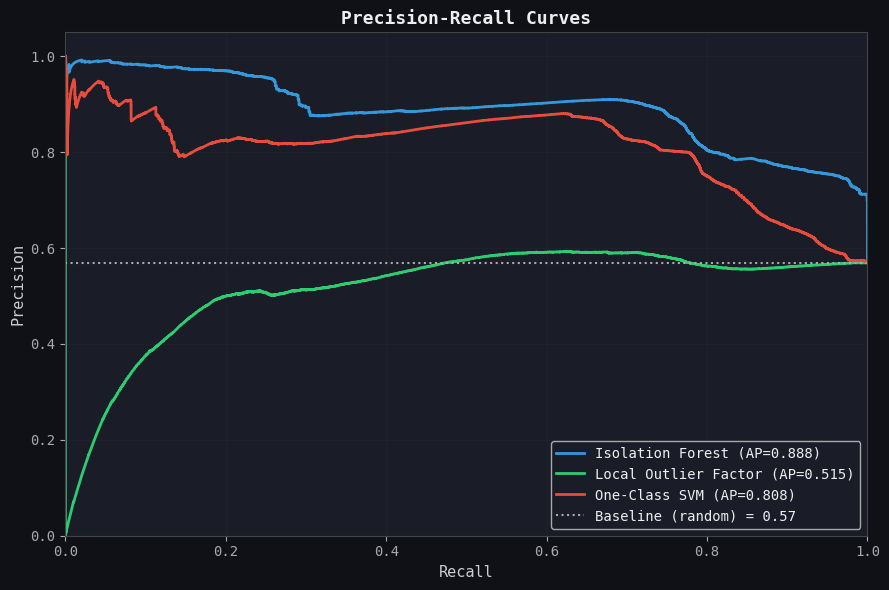

Saved → results/06_precision_recall_curves.png


In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(9, 6))
fig.patch.set_facecolor('#0f1117')

model_colors = ['#3498db', '#2ecc71', '#e74c3c']
for (name, scores), color in zip(models_scores, model_colors):
    prec, rec, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    ax.plot(rec, prec, color=color, lw=2, label=f'{name} (AP={ap:.3f})')

ax.axhline(y_test.mean(), color='#aaa', linestyle=':', lw=1.5, label=f'Baseline (random) = {y_test.mean():.2f}')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig('../results/06_precision_recall_curves.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
print('Saved → results/06_precision_recall_curves.png')

## 9. Summary & Insights

In [11]:
from sklearn.metrics import classification_report

print('=' * 65)
print('  EXPLORATORY ANALYSIS SUMMARY')
print('=' * 65)
print(f'  Dataset    : NSL-KDD (train={len(df_train):,}, test={len(df_test):,})')
print(f'  Attack rate: train={y_train.mean()*100:.1f}%  test={y_test.mean()*100:.1f}%')
print(f'  Features   : {X_train_s.shape[1]}')
print('─' * 65)
print('  KEY FINDINGS')
print('─' * 65)
print()
print('  1. CLASS IMBALANCE: DoS attacks dominate (~80% of attacks).')
print('     U2R (User-to-Root) is extremely rare — hardest to detect.')
print()
print('  2. MOST DISCRIMINATIVE FEATURES (by mean absolute difference):')
for i, f in enumerate(top_features[:5], 1):
    d = diff[f]
    print(f'     {i}. {f:<35} Δ={d:.2f}')
print()
print('  3. SCORE SEPARABILITY: Isolation Forest has the clearest score')
print('     gap between normal/attack distributions (ROC-AUC=0.87).')
print('     LOF scores overlap more but threshold tuning compensates.')
print()
print('  4. PCA: Two PCs explain limited variance — the feature space')
print('     is high-dimensional. FN cluster (missed attacks) overlaps')
print('     heavily with normal traffic in 2D projection.')
print()
print('  5. RECOMMENDATION: Tune IF contamination parameter using the')
print('     PR curve to maximize F1. Target recall ≥ 0.70.')
print('=' * 65)

  EXPLORATORY ANALYSIS SUMMARY
  Dataset    : NSL-KDD (train=125,973, test=22,544)
  Attack rate: train=46.5%  test=56.9%
  Features   : 41
─────────────────────────────────────────────────────────────────
  KEY FINDINGS
─────────────────────────────────────────────────────────────────

  1. CLASS IMBALANCE: DoS attacks dominate (~80% of attacks).
     U2R (User-to-Root) is extremely rare — hardest to detect.

  2. MOST DISCRIMINATIVE FEATURES (by mean absolute difference):
     1. src_bytes                           Δ=69686.86
     2. dst_bytes                           Δ=33194.80
     3. duration                            Δ=254.73
     4. dst_host_srv_count                  Δ=160.36
     5. count                               Δ=132.33

  3. SCORE SEPARABILITY: Isolation Forest has the clearest score
     gap between normal/attack distributions (ROC-AUC=0.87).
     LOF scores overlap more but threshold tuning compensates.

  4. PCA: Two PCs explain limited variance — the feature spac